In [50]:
# Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import pyarrow

# Importing libraries for KMeans and Heirarchical Clustering
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Specific for mycase as I'm using Jupyter in VSC
import plotly.io as pio
pio.renderers.default='notebook'

In [51]:
import warnings
warnings.filterwarnings("ignore")

In [52]:
# Load daily basin
df = pd.read_parquet(r"data\model_dfs\basin_daily_model.parquet")

In [53]:
df.columns

Index(['date', 'basin_swe', 'basin_precip_increment', 'n_snow_stations',
       'temp_mean', 'temp_mean_lag1', 'temp_7d_mean', 'temp_14d_mean',
       'precipitation', 'precip_lag1', 'precip_7d', 'precip_14d', 'precip_30d',
       'temp_precip_interaction', 'doy_sin', 'doy_cos', 'n_climate_stations'],
      dtype='object')

In [54]:
df['date'] = pd.to_datetime(df['date'])
df['month'] = df['date'].dt.month

#df = df[
#    df['month'].isin([11, 12, 1, 2, 3, 4, 5])
#].copy()

In [55]:
features = [
    'temp_mean',
    'temp_14d_mean',
    'precip_7d',
    'precip_14d',
    'precip_30d',
    'doy_sin',
    'doy_cos'
]

cluster_df = df[
    features
].dropna().copy()

scaler_cluster = StandardScaler()

X_scaled = scaler_cluster.fit_transform(
    cluster_df[features]
)
X = pd.DataFrame(
    X_scaled,
    columns=features,
    index=cluster_df.index
)

In [56]:
corr = df[features].corr()
corr.style.background_gradient(cmap='coolwarm')

,temp_mean,temp_14d_mean,precip_7d,precip_14d,precip_30d,doy_sin,doy_cos
temp_mean,1.000000,0.940326,0.098554,0.169356,0.263180,-0.298484,-0.879721
temp_14d_mean,0.940326,1.000000,0.183971,0.220518,0.299273,-0.412422,-0.879250
precip_7d,0.098554,0.183971,1.000000,0.748225,0.539123,-0.069270,-0.184939
precip_14d,0.169356,0.220518,0.748225,1.000000,0.734006,-0.107397,-0.240985
precip_30d,0.263180,0.299273,0.539123,0.734006,1.000000,-0.187383,-0.303704
doy_sin,-0.298484,-0.412422,-0.069270,-0.107397,-0.187383,1.000000,0.004378
doy_cos,-0.879721,-0.879250,-0.184939,-0.240985,-0.303704,0.004378,1.000000


In [57]:
print(X.shape)

(13403, 7)


In [58]:
print(X.isna().sum())

temp_mean        0
temp_14d_mean    0
precip_7d        0
precip_14d       0
precip_30d       0
doy_sin          0
doy_cos          0
dtype: int64


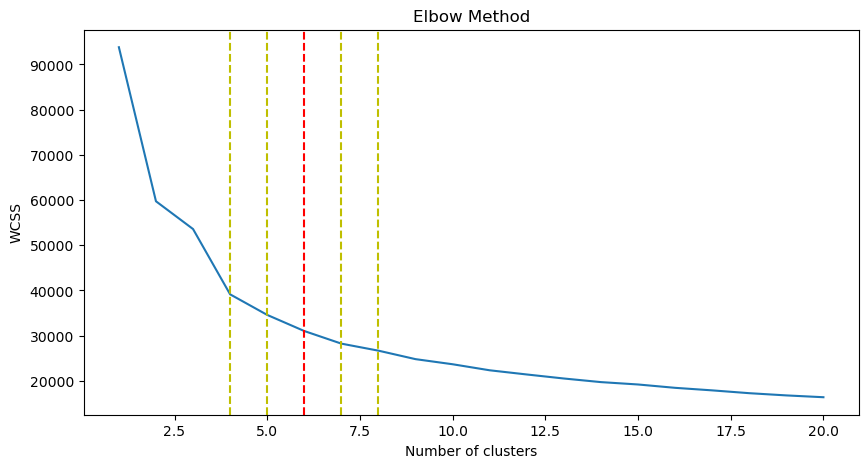

[93820.99999999999, 59731.596056661736, 53585.29488191367, 39135.296437561985, 34583.1915013419, 31017.826572542996, 28227.6104843372, 26671.41073258958, 24795.340837024574, 23665.81670996474, 22328.699112333088, 21402.7519786545, 20511.94470955235, 19713.490497159743, 19189.24587560378, 18448.339917471458, 17885.498276796294, 17261.79705474307, 16770.547249577277, 16369.162472935357]


In [59]:
# Performing KMeans clustering with upto 20 clusters and plotting the elbow plot with wcss
# use the following for your kmeans parameters: init='k-means++', max_iter=300, n_init=10, random_state=0

wcss = []
for i in range(1, 21):
    # your code here
    kmeans = KMeans(n_clusters = i)
    kmeans.fit(X)
        
    wcss.append(kmeans.inertia_)
    
# Plotting the elbow plot
plt.figure(figsize=(10, 5))
plt.plot(range(1, 21), wcss)

# Add dashed line at 5,6,7,8 clusters
plt.axvline(x=4, color='y', linestyle='--')
plt.axvline(x=5, color='y', linestyle='--')
plt.axvline(x=6, color='r', linestyle='--')
plt.axvline(x=7, color='y', linestyle='--')
plt.axvline(x=8, color='y', linestyle='--')
plt.title('Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

print(wcss)

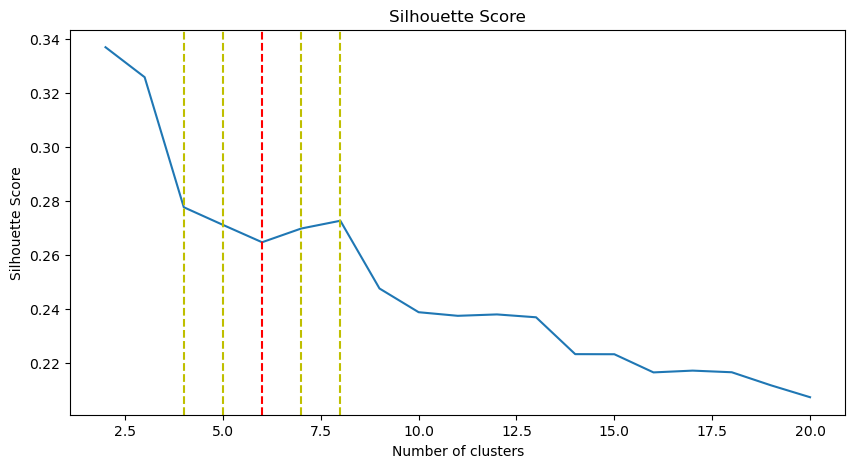

[np.float64(0.3370497091440653), np.float64(0.32594818838893974), np.float64(0.2777683855407744), np.float64(0.27123270436333846), np.float64(0.26480061362805535), np.float64(0.26988566174306583), np.float64(0.27276477394176), np.float64(0.2476677313148835), np.float64(0.23888371493173832), np.float64(0.23754800693918296), np.float64(0.23806262159378228), np.float64(0.2370015932836648), np.float64(0.2233505368267036), np.float64(0.2233131064423817), np.float64(0.21658352863903735), np.float64(0.2172444977846414), np.float64(0.2166387983755102), np.float64(0.21180591452667155), np.float64(0.2073890831110036)]


In [60]:
# Performing KMeans clustering with upto 20 clusters and plotting the silhouette score
# use the following for your kmeans parameters: init='k-means++', max_iter=300, n_init=10, random_state=0

silhouette_score_list = []
for i in range(2, 21):
    # your code here
    kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10,random_state=0)
    cluster_labels = kmeans.fit_predict(X)
    score = silhouette_score(X, cluster_labels)
    silhouette_score_list.append(score)
    
# Plotting the silhouette score
plt.figure(figsize=(10, 5))
plt.plot(range(2, 21), silhouette_score_list)

# Add dashed line at 5,6,7,8 clusters
plt.axvline(x=4, color='y', linestyle='--')
plt.axvline(x=5, color='y', linestyle='--')
plt.axvline(x=6, color='r', linestyle='--')
plt.axvline(x=7, color='y', linestyle='--')
plt.axvline(x=8, color='y', linestyle='--')
plt.title('Silhouette Score')
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette Score')
plt.show()

print(silhouette_score_list)

In [61]:
for k in [4, 5, 6]:

    km = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=10,
        max_iter=300,
        random_state=0
    )

    labels = km.fit_predict(X)

    temp_df = cluster_df.copy()
    temp_df['cluster'] = labels

    print(f"\n--- k = {k} ---")

    print(
        temp_df
        .groupby('cluster')[features]
        .mean()
        .round(2)
    )


--- k = 4 ---
         temp_mean  temp_14d_mean  precip_7d  precip_14d  precip_30d  doy_sin  \
cluster                                                                         
0            24.75          25.76       0.16        0.33        0.74    -0.03   
1            59.70          59.30       0.15        0.35        0.94    -0.41   
2            52.89          54.21       0.60        1.05        1.84    -0.32   
3            40.03          37.79       0.20        0.43        0.93     0.90   

         doy_cos  
cluster           
0           0.80  
1          -0.59  
2          -0.45  
3          -0.14  

--- k = 5 ---
         temp_mean  temp_14d_mean  precip_7d  precip_14d  precip_30d  doy_sin  \
cluster                                                                         
0            40.02          37.79       0.21        0.43        0.94     0.91   
1            21.75          22.32       0.16        0.33        0.72     0.20   
2            53.28          54.56       0.61 

In [62]:
features = X.columns.tolist()

In [63]:
# creating parallel plots to visualize the clusters centroids

kmeans = KMeans(
    n_clusters=4,
    init='k-means++',
    max_iter=300,
    n_init=10,
    random_state=0
)

cluster_labels = kmeans.fit_predict(X)

X_clustered = X.copy()
X_clustered['cluster'] = cluster_labels

fig = px.parallel_coordinates(X_clustered, color='cluster', color_continuous_scale=px.colors.sequential.Viridis)
pio.renderers.default = "iframe"
fig.show()


In [64]:
cluster_df['cluster'] = kmeans.fit_predict(
    X_scaled
)

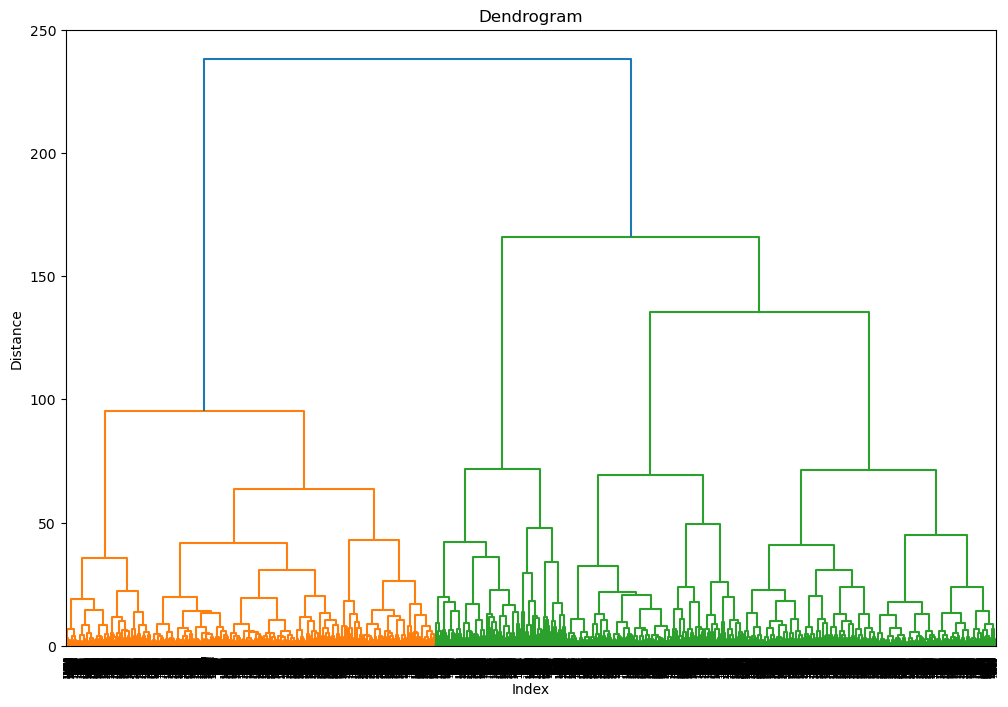

In [65]:
# Performing Heirarchical clustering and plotting the dendrogram

Z = linkage(X, 'ward')

plt.figure(figsize=(12, 8))
dendrogram(Z)
plt.title('Dendrogram')
plt.xlabel('Index')
plt.ylabel('Distance')
plt.show()

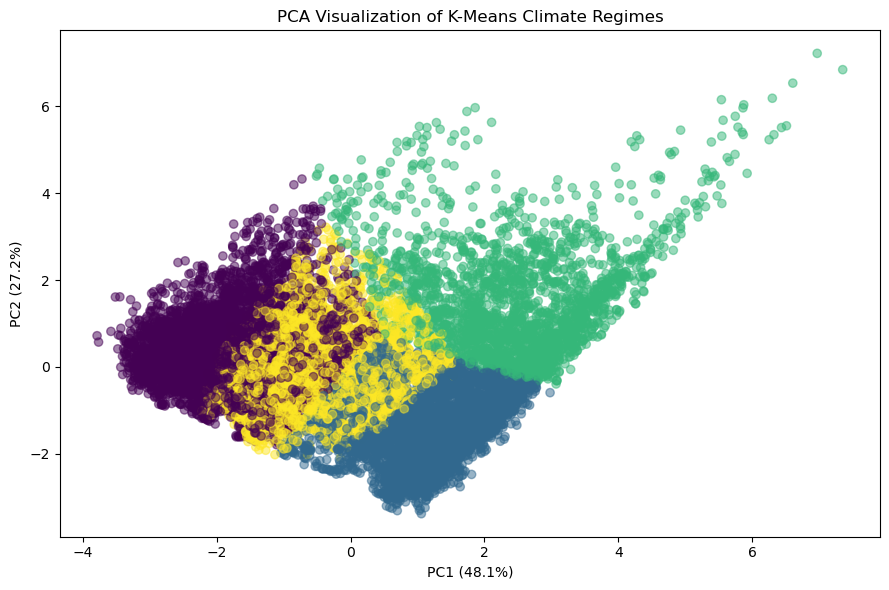

In [66]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(
    X_clustered[features]
)

plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cluster_labels,
    alpha=0.5
)

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"
)

plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)"
)

plt.title("PCA Visualization of K-Means Climate Regimes")

plt.tight_layout()
plt.show()

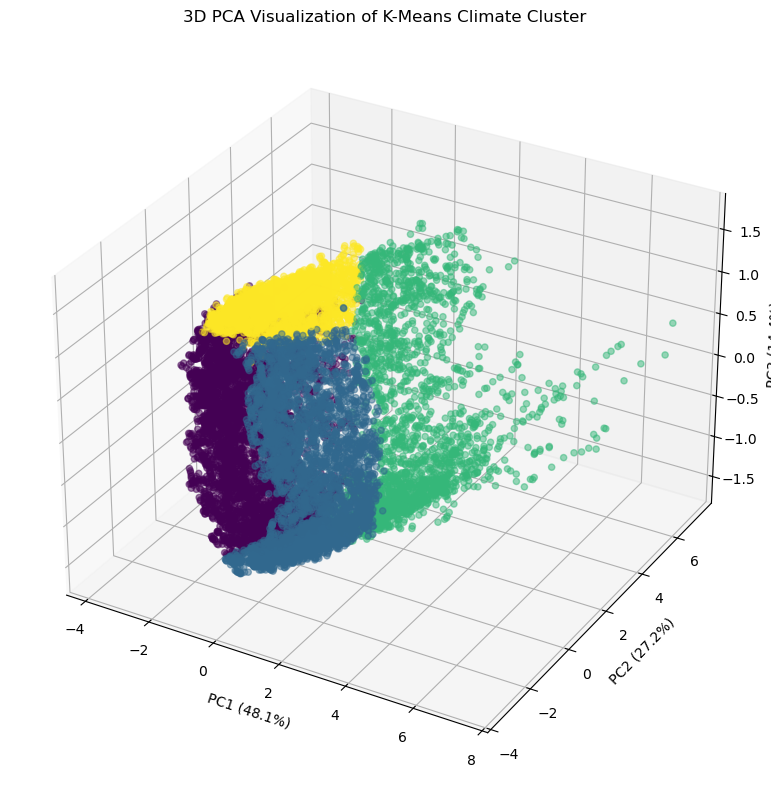

In [68]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# PCA with 3 components
pca = PCA(n_components=3)

X_pca = pca.fit_transform(
    X_clustered[features]
)

# 3D plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    X_pca[:, 2],
    c=cluster_labels,
    alpha=0.5
)

ax.set_xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"
)

ax.set_ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)"
)

ax.set_zlabel(
    f"PC3 ({pca.explained_variance_ratio_[2]*100:.1f}%)"
)

ax.set_title(
    "3D PCA Visualization of K-Means Climate Cluster"
)

plt.tight_layout()


plt.savefig(
    "figures/kmeans_pca_3d.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [45]:
cluster_summary = (
    cluster_df
    .groupby('cluster')[features]
    .mean()
    .round(2)
)

cluster_summary

,temp_mean,temp_14d_mean,precip_7d,precip_14d,precip_30d,doy_sin,doy_cos
cluster,,,,,,,
0,24.75,25.76,0.16,0.33,0.74,-0.03,0.80
1,59.70,59.30,0.15,0.35,0.94,-0.41,-0.59
2,52.89,54.21,0.60,1.05,1.84,-0.32,-0.45
3,40.03,37.79,0.20,0.43,0.93,0.90,-0.14


In [46]:
cluster_names = {
    0: 'Cold / Dry',
    1: 'Warm / Dry',
    2: 'Warm / Wet',
    3: 'Cool / Transitional'
}

cluster_df['cluster_name'] = (
    cluster_df['cluster']
    .map(cluster_names)
)

In [47]:
cluster_df

,temp_mean,temp_14d_mean,precip_7d,precip_14d,precip_30d,doy_sin,doy_cos,cluster,cluster_name
19,19.833333,23.738095,0.173333,0.246667,0.346667,0.337301,0.941397,0,Cold / Dry
20,14.333333,23.964286,0.113333,0.246667,0.346667,0.353445,0.935455,0,Cold / Dry
21,15.666667,23.690476,0.043333,0.233333,0.346667,0.369484,0.929237,0,Cold / Dry
22,21.833333,23.178571,0.020000,0.180000,0.346667,0.385413,0.922744,0,Cold / Dry
23,19.000000,22.428571,0.050000,0.203333,0.376667,0.401229,0.915978,0,Cold / Dry
...,...,...,...,...,...,...,...,...,...
13417,54.666667,59.821429,0.123333,1.026667,1.660000,-0.996395,-0.084835,2,Warm / Wet
13418,58.166667,59.261905,0.113333,1.013333,1.660000,-0.997707,-0.067683,2,Warm / Wet
13419,57.000000,58.690476,0.173333,0.986667,1.716667,-0.998724,-0.050511,2,Warm / Wet
13420,55.750000,58.732143,0.190000,0.995000,1.595000,-0.999445,-0.033324,2,Warm / Wet


SAVE MODEL

In [49]:
import joblib
from pathlib import Path

model_dir = Path("data/models")
model_dir.mkdir(parents=True, exist_ok=True)

cluster_bundle = {
    "model": kmeans,
    "scaler": scaler_cluster,
    "features": features,
    "cluster_names": cluster_names
}

joblib.dump(
    cluster_bundle,
    model_dir / "kmeans_climate_regimes.joblib"
)

print("K-means climate regime model saved.")

K-means climate regime model saved.


RELOAD

In [ ]:
bundle = joblib.load(
    "data/models/kmeans_climate_regimes.joblib"
)

kmeans_final = bundle["model"]
scaler_cluster = bundle["scaler"]
features = bundle["features"]
cluster_names = bundle["cluster_names"]